In [4]:

import geopandas as gpd
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import contextily


In [5]:

gdf = gpd.read_file('../data/tmp/dst_v3.gpkg')



In [6]:
gdf_coco = gdf.loc[gdf.driver == 'cocoa']

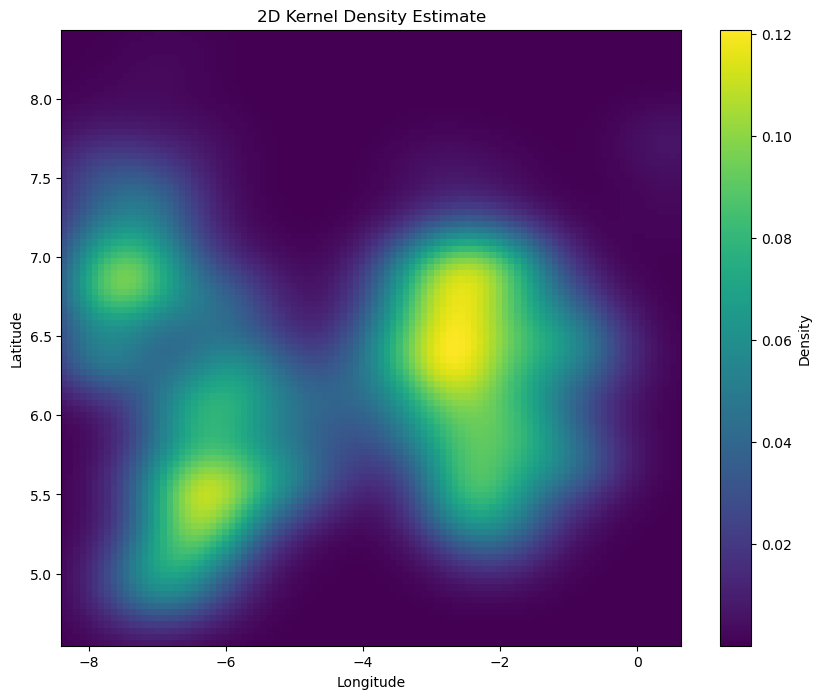

In [11]:



# Step 2: Extract x and y coordinates
x = gdf_coco.geometry.x.values
y = gdf_coco.geometry.y.values
data = np.vstack([x, y])

# Step 3: Compute KDE
kde = gaussian_kde(data)

# Step 4: Create a grid over which to evaluate the KDE
xmin, ymin, xmax, ymax = gdf_coco.total_bounds
xgrid = np.linspace(xmin, xmax, 100)
ygrid = np.linspace(ymin, ymax, 100)
X, Y = np.meshgrid(xgrid, ygrid)
grid_coords = np.vstack([X.ravel(), Y.ravel()])

# Step 5: Evaluate the KDE on the grid
Z = kde(grid_coords).reshape(X.shape)

# Step 6: Plot the results
plt.figure(figsize=(10, 8))
plt.imshow(Z, origin='lower', aspect='auto', extent=[xmin, xmax, ymin, ymax], cmap='viridis')
#plt.scatter(x, y, s=1, color='red') # optionally, plot the original points
plt.colorbar(label='Density')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('2D Kernel Density Estimate')
plt.show()

In [23]:
kde(grid_coords).shape

(10000,)

In [26]:
Y.shape


(100, 100)

array([[-8.40573289, -8.31429874, -8.22286459, ...,  0.46337971,
         0.55481386,  0.64624802],
       [-8.40573289, -8.31429874, -8.22286459, ...,  0.46337971,
         0.55481386,  0.64624802],
       [-8.40573289, -8.31429874, -8.22286459, ...,  0.46337971,
         0.55481386,  0.64624802],
       ...,
       [-8.40573289, -8.31429874, -8.22286459, ...,  0.46337971,
         0.55481386,  0.64624802],
       [-8.40573289, -8.31429874, -8.22286459, ...,  0.46337971,
         0.55481386,  0.64624802],
       [-8.40573289, -8.31429874, -8.22286459, ...,  0.46337971,
         0.55481386,  0.64624802]])

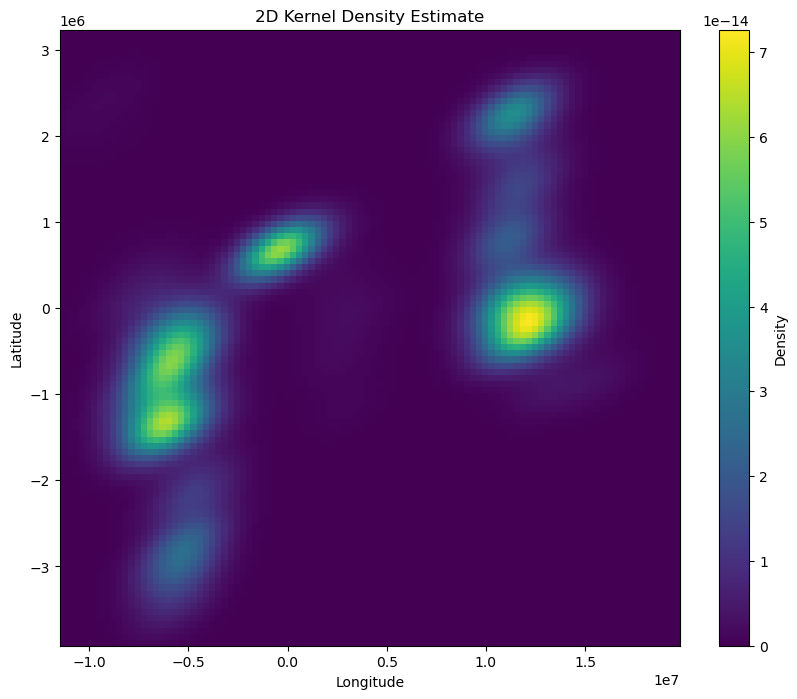

In [24]:

# Load, extract, compute KDE as before

# Transform the GeoDataFrame to Web Mercator for contextily compatibility
gdf = gdf.to_crs(epsg=3857)

# Extract transformed x and y coordinates
x = gdf.geometry.x.values
y = gdf.geometry.y.values
data = np.vstack([x, y])

# KDE computation as before

# Create a grid over which to evaluate the KDE, transformed to Web Mercator
xmin, ymin, xmax, ymax = gdf.total_bounds
xgrid = np.linspace(xmin, xmax, 100)
ygrid = np.linspace(ymin, ymax, 100)
X, Y = np.meshgrid(xgrid, ygrid)
grid_coords = np.vstack([X.ravel(), Y.ravel()])

# Evaluate the KDE on the grid
Z = kde(grid_coords).reshape(X.shape)

# Step 6: Plot the results
plt.figure(figsize=(10, 8))
plt.imshow(Z, origin='lower', aspect='auto', extent=[xmin, xmax, ymin, ymax], cmap='viridis')
#plt.scatter(x, y, s=1, color='red') # optionally, plot the original points
plt.colorbar(label='Density')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('2D Kernel Density Estimate')
plt.show()

In [34]:
Z

array([[2.41397974e-18, 5.64497117e-18, 1.24782180e-17, ...,
        3.27626464e-35, 6.66606247e-36, 1.25772113e-36],
       [2.68383344e-18, 6.32118882e-18, 1.41187402e-17, ...,
        1.15699109e-33, 2.50994325e-34, 5.04926693e-35],
       [2.98282385e-18, 7.04603376e-18, 1.57988161e-17, ...,
        3.46850193e-32, 8.02235478e-33, 1.72067872e-33],
       ...,
       [4.78211832e-18, 9.31650310e-18, 1.69155056e-17, ...,
        9.87005371e-21, 3.17654556e-21, 1.00413426e-21],
       [2.04690771e-18, 4.21671550e-18, 8.08127144e-18, ...,
        7.68343956e-21, 2.48684545e-21, 7.69377512e-22],
       [7.56997628e-19, 1.65324137e-18, 3.35542594e-18, ...,
        5.52965871e-21, 1.84127307e-21, 5.78025301e-22]])

/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/contextily/tile.py:614: UserWarning: The inferred zoom level of 27 is not valid for the current tile provider (valid zooms: 0 - 19).
  warnings.warn(msg)


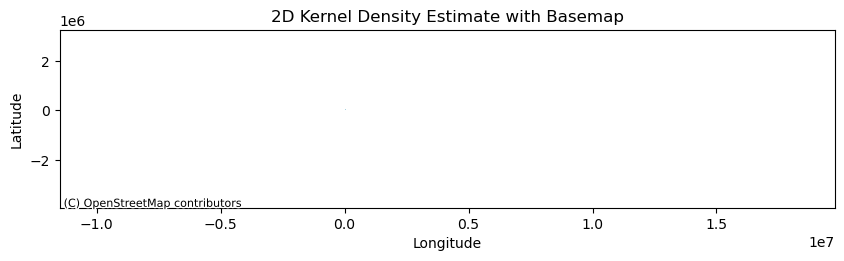

In [36]:


# Load, extract, compute KDE as before

# Transform the GeoDataFrame to Web Mercator for contextily compatibility
gdf = gdf.to_crs(epsg=3857)

# Extract transformed x and y coordinates
x = gdf.geometry.x.values
y = gdf.geometry.y.values
data = np.vstack([x, y])

# KDE computation as before

# Create a grid over which to evaluate the KDE, transformed to Web Mercator
xmin, ymin, xmax, ymax = gdf.total_bounds
xgrid = np.linspace(xmin, xmax, 100)
ygrid = np.linspace(ymin, ymax, 100)
X, Y = np.meshgrid(xgrid, ygrid)
grid_coords = np.vstack([X.ravel(), Y.ravel()])

# Evaluate the KDE on the grid
Z = kde(grid_coords).reshape(X.shape)

# Plot KDE
fig, ax = plt.subplots(figsize=(10, 8))
#ax.imshow(Z, origin='lower', aspect='auto', extent=[xmin, xmax, ymin, ymax], cmap='viridis', alpha=0.6)  # Adjust alpha for basemap visibility
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)  # Add a basemap

# Adjust the plot limits to the data extent
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

## Optionally, re-project and plot original points for reference
#gdf_points = gpd.GeoDataFrame(geometry=gpd.points_from_xy(x, y), crs='EPSG:3857')
#gdf_points.plot(ax=ax, color='red', markersize=1)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('2D Kernel Density Estimate with Basemap')
plt.show()

In [21]:
Z.max()

0.0

In [ ]:
# Assuming the loading of GeoPackage, extraction of coordinates, and KDE computation are done

# Transform the GeoDataFrame to Web Mercator (EPSG:3857) for basemap compatibility
gdf_coco = gdf.loc[gdf.driver == 'cocoa']
gdf = gdf.to_crs(epsg=3857)

# Create a grid over which to evaluate the KDE, in Web Mercator coordinates
xmin, ymin, xmax, ymax = gdf_coco.total_bounds
xgrid = np.linspace(xmin, xmax, 100)
ygrid = np.linspace(ymin, ymax, 100)
X, Y = np.meshgrid(xgrid, ygrid)
grid_coords = np.vstack([X.ravel(), Y.ravel()])

# Evaluate the KDE on the grid
Z = kde(grid_coords).reshape(X.shape)

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Add a basemap

# Overlay the KDE plot. Use extent and alpha for visibility and proper placement
# Convert the bounds back to Web Mercator for correct overlay
#xmin, ymin, xmax, ymax = [val for val in gdf.total_bounds]
ax.imshow(Z, origin='lower', extent=[xmin, xmax, ymin, ymax], cmap='viridis', alpha=0.6, aspect='auto')

# Optionally, plot the points
gdf_coco.plot(ax=ax, marker='o', color='red', markersize=0.05)
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, zoom=19)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.show()

In [49]:
Z.shape

(100, 100)

## TMP plotting

In [50]:
import pandas as pd
path = '/home/jan/Documents/EPFL/project_2/data/tmp/FAOSTAT_data_en_2-22-2024.csv'

In [114]:
df = pd.read_csv(path)

In [105]:
df = df.loc[df.Area != 'Congo']
df = df.loc[df.Area != 'Peru']
df = df.loc[df.Area != 'DRC']

In [115]:
df = df[[ 'Area',   'Item', 'Value']]

In [116]:
palm_oil_prod = df.loc[df.Item == 'Oil palm fruit'].Value.tolist()
soy_prod = df.loc[df.Item == 'Soya beans'].Value.tolist()
coco_prod = df.loc[df.Item == 'Cocoa beans'].Value.tolist()

In [117]:
x = ['Brazil', 'Cameroon', "Côte \nd'Ivoire",
       'DRC', 'Ecuador', 'Ghana',
       'Indonesia', 'Malaysia', 'Peru']

In [118]:
total_area = {
    'Brazil': 8515767,
    'Cameroon': 475442,
    "Côte d'Ivoire": 322463,
    'DRC': 2344858,
    'Ecuador': 256369,
    'Ghana': 238533,
    'Indonesia': 1904569,
    'Malaysia': 330803,
    'Peru': 1285216
}

In [119]:

areas = [val for key, val in total_area.items()]

In [123]:
palm_oil_prod

[200527,
 206624,
 12658,
 400000,
 348146,
 141381,
 365678,
 14953126,
 5135576,
 91947]

In [121]:
palm_oil_prod_norm = [a/b for a,b in zip(palm_oil_prod,areas)]
soy_prod_norm = [a/b for a,b in zip(soy_prod,areas)]
coco_prod_norm = [a/b for a,b in zip(coco_prod,areas)]

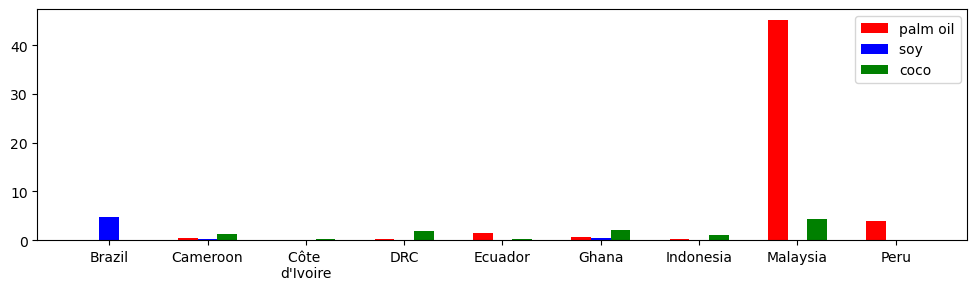

In [122]:
#x = df.Area.unique()
_x = np.arange(len(x)) 

fig, ax = plt.subplots(1,figsize=(12,3))
ax.bar(_x-0.2, palm_oil_prod_norm, width=0.2, color='r', align='center', label='palm oil')
ax.bar(_x, soy_prod_norm, width=0.2, color='b', align='center', label='soy ')
ax.bar(_x+0.2, coco_prod_norm, width=0.2, color='g', align='center', label='coco')
plt.xticks(_x, x) 
plt.legend()
plt.show()